# Global GDP Ranking 2026: Where Does Taiwan Stand?

**Author:** Pin-Hsuan (Jane) Lee · University of Warwick

**Business questions**
1. Which economies are the largest in 2026 by **total GDP**, **GDP per capita** and **GDP per capita (PPP)**?
2. Where does **Taiwan** rank on each measure, and why do the three rankings differ so much?
3. Among the 30 largest economies, how do **inflation** and **real GDP growth** compare?

**Data:** IMF World Economic Outlook (October 2026), pulled live from the [IMF DataMapper API](https://www.imf.org/external/datamapper/api/help).
**Tools:** Python (requests, pandas, matplotlib), Jupyter.

| Indicator | IMF code | Unit |
|---|---|---|
| GDP, current prices | `NGDPD` | billions of USD |
| GDP per capita, current prices | `NGDPDPC` | USD |
| GDP per capita, PPP | `PPPPC` | international dollars |
| Inflation, average consumer prices | `PCPIPCH` | annual % change |
| Real GDP growth | `NGDP_RPCH` | annual % change |
| Population | `LP` | millions |

## 1. Setup

In [1]:
import os
import json
import requests
import pandas as pd
import matplotlib.pyplot as plt

BASE_URL = "https://www.imf.org/external/datamapper/api/v2/"
YEAR = "2026"          # IMF uses text keys for years, so this is a string

# IMF code -> readable column name
INDICATORS = {
    "NGDPD":     "gdp_usd_bn",
    "NGDPDPC":   "gdp_per_capita_usd",
    "PPPPC":     "gdp_per_capita_ppp",
    "PCPIPCH":   "inflation_pct",
    "NGDP_RPCH": "real_growth_pct",
    "LP":        "population_mn",
}

# Taiwan and the economies it is most often compared with
PEERS = ["TWN", "KOR", "JPN", "SGP", "HKG", "CHN", "USA", "GBR", "DEU"]

os.makedirs("data", exist_ok=True)
os.makedirs("images", exist_ok=True)

## 2. Get the data

The API returns nested JSON: `values → indicator code → country code → {year: value}`.

The response also contains **regional aggregates** (e.g. *World*, *Euro area*), not just countries.
In the first test pull, `NGDPD` had 229 entries but only 197 were real economies. If the aggregates
stay in, they take over the top of the ranking. So I fetch the IMF's own list of countries and keep only those.

In [2]:
response = requests.get(BASE_URL + "countries", timeout=30)
response.raise_for_status()                 # stop here if the request failed
countries = response.json()["countries"]    # {code: {"label": name}}

country_names = {code: info.get("label") for code, info in countries.items()}
print(len(country_names), "economies in the IMF country list")
print("TWN ->", country_names.get("TWN"))

241 economies in the IMF country list
TWN -> Taiwan Province of China


In [3]:
def get_indicator(code):
    '''Download one IMF indicator and return a table: rows = countries, columns = years.'''
    response = requests.get(BASE_URL + code, timeout=30)
    response.raise_for_status()
    data = response.json()["values"][code]          # {country: {year: value}}
    table = pd.DataFrame(data).T                     # transpose so each country is a row
    table = table[table.index.isin(country_names)]   # drop regional aggregates
    return table.apply(pd.to_numeric, errors="coerce")


tables = {}
for code, name in INDICATORS.items():
    tables[name] = get_indicator(code)
    print(f"{code:10} -> {name:20} {tables[name].shape}")

NGDPD      -> gdp_usd_bn           (197, 52)
NGDPDPC    -> gdp_per_capita_usd   (197, 52)
PPPPC      -> gdp_per_capita_ppp   (197, 52)
PCPIPCH    -> inflation_pct        (197, 52)
NGDP_RPCH  -> real_growth_pct      (197, 52)
LP         -> population_mn        (197, 52)


In [4]:
# Keep a copy of the full raw history (all years) in long format: one row = country, indicator, year
raw_long = pd.concat(
    {name: t.stack().dropna() for name, t in tables.items()}, names=["indicator", "country_code", "year"]
).rename("value").reset_index()
raw_long.to_csv("data/imf_weo_oct2026_raw.csv", index=False)
print(raw_long.shape)
raw_long.head()

(55706, 4)


,indicator,country_code,year,value
0,gdp_usd_bn,SDN,1980,9.095
1,gdp_usd_bn,SDN,1981,6.530
2,gdp_usd_bn,SDN,1982,4.748
3,gdp_usd_bn,SDN,1983,6.485
4,gdp_usd_bn,SDN,1984,7.992


## 3. Clean and combine

One row per economy, one column per indicator, for 2026 only.

*Naming note:* the IMF labels Taiwan "Taiwan Province of China". I display it as "Taiwan" for readability; the code `TWN` is unchanged.

In [5]:
df = pd.DataFrame({name: t[YEAR] for name, t in tables.items()})
df.index.name = "country_code"
df.insert(0, "country", df.index.map(country_names))

# Shorter display names for charts (IMF labels such as "Korea, Republic of" are long)
SHORT_NAMES = {"TWN": "Taiwan", "KOR": "South Korea", "CHN": "China", "HKG": "Hong Kong",
               "USA": "United States", "GBR": "United Kingdom", "RUS": "Russia", "TUR": "Türkiye",
               "IRN": "Iran", "NLD": "Netherlands", "SAU": "Saudi Arabia", "ARE": "UAE"}
for c, n in SHORT_NAMES.items():
    if c in df.index:
        df.loc[c, "country"] = n

# Price level ratio: nominal GDP per capita / PPP GDP per capita.
# Below 1 means goods and services are cheaper than in the US, so the same income buys more locally.
df["price_level_ratio"] = df["gdp_per_capita_usd"] / df["gdp_per_capita_ppp"]

df.to_csv("data/gdp_2026_clean.csv")
print(df.shape)
df.loc[PEERS]

(197, 8)


,country,gdp_usd_bn,gdp_per_capita_usd,gdp_per_capita_ppp,inflation_pct,real_growth_pct,population_mn,price_level_ratio
country_code,,,,,,,,
TWN,Taiwan,1019.596,43950.969,103743.323,2.0,10.7,23.198,0.423651
KOR,South Korea,2245.847,43511.885,70250.966,2.7,3.3,51.615,0.619378
JPN,Japan,4341.986,35399.602,59711.992,2.0,0.7,122.656,0.592839
SGP,Singapore,667.889,109116.828,176927.023,2.3,5.0,6.121,0.616734
HKG,Hong Kong,455.156,60321.859,85843.332,1.9,3.8,7.545,0.702697
CHN,China,21546.403,15371.258,31785.615,1.0,4.5,1401.733,0.483592
USA,United States,32642.373,95212.135,95212.135,3.6,2.3,342.838,1.000000
GBR,United Kingdom,4268.446,61108.378,68476.346,3.3,1.3,69.850,0.892401
DEU,Germany,5471.299,65699.222,78664.175,2.7,1.3,83.278,0.835186


In [6]:
# Data quality: how many economies have no 2026 figure for each indicator?
missing = df.drop(columns="country").isna().sum()
print(missing)
print("\nNo 2026 GDP figure:", ", ".join(df.loc[df["gdp_usd_bn"].isna(), "country"].astype(str)))

gdp_usd_bn            6
gdp_per_capita_usd    6
gdp_per_capita_ppp    6
inflation_pct         6
real_growth_pct       6
population_mn         6
price_level_ratio     6
dtype: int64

No 2026 GDP figure: Afghanistan, Eritrea, Lebanon, Senegal, Syria, West Bank and Gaza


## 4. Rankings: top 30 on three measures

In [7]:
MEASURES = {
    "gdp_usd_bn":         "Total GDP (USD bn)",
    "gdp_per_capita_usd": "GDP per capita (USD)",
    "gdp_per_capita_ppp": "GDP per capita (PPP, int. $)",
}

ranked = {}
for col, label in MEASURES.items():
    top = df[["country", col]].dropna().sort_values(col, ascending=False).head(30)
    ranked[label] = (top["country"] + " (" + top[col].round(0).astype(int).map("{:,}".format) + ")").values

top30 = pd.DataFrame(ranked, index=range(1, 31))
top30.index.name = "rank"
top30.to_csv("data/top30_rankings_2026.csv")
top30

,Total GDP (USD bn),GDP per capita (USD),"GDP per capita (PPP, int. $)"
rank,,,
1,"United States (32,642)","Liechtenstein (230,417)","Liechtenstein (198,987)"
2,"China (21,546)","Luxembourg (155,733)","Singapore (176,927)"
3,"Germany (5,471)","Ireland (127,837)","Luxembourg (156,638)"
4,"Japan (4,342)","Switzerland (124,478)","Ireland (149,642)"
5,"United Kingdom (4,268)","Norway (115,188)","Macao SAR (141,442)"
6,"India (4,060)","Singapore (109,117)","Norway (116,169)"
7,"France (3,554)","Iceland (107,464)","Switzerland (106,944)"
8,"Russia (2,861)","United States (95,212)","Qatar (103,804)"
9,"Italy (2,702)","Denmark (82,714)","Taiwan (103,743)"


In [8]:
# Taiwan's position on each measure
rank_rows = []
for col, label in MEASURES.items():
    valid = df[col].dropna()
    rank = int(valid.rank(ascending=False, method="min")["TWN"])
    rank_rows.append({"measure": label, "taiwan_value": round(df.loc["TWN", col], 1),
                      "rank": rank, "out_of": len(valid)})

taiwan_rank = pd.DataFrame(rank_rows)
taiwan_rank

,measure,taiwan_value,rank,out_of
0,Total GDP (USD bn),1019.6,22,191
1,GDP per capita (USD),43951.0,31,191
2,"GDP per capita (PPP, int. $)",103743.3,9,191


## 5. Taiwan vs. its peers

The three measures tell different stories. Total GDP rewards size. GDP per capita converts at market exchange rates,
so a weak currency pulls it down. PPP adjusts for local prices.

In [9]:
peers = df.loc[PEERS, ["country", "gdp_usd_bn", "gdp_per_capita_usd", "gdp_per_capita_ppp",
                       "price_level_ratio", "real_growth_pct", "inflation_pct"]]
peers.sort_values("gdp_per_capita_ppp", ascending=False).round(2)

,country,gdp_usd_bn,gdp_per_capita_usd,gdp_per_capita_ppp,price_level_ratio,real_growth_pct,inflation_pct
country_code,,,,,,,
SGP,Singapore,667.89,109116.83,176927.02,0.62,5.0,2.3
TWN,Taiwan,1019.60,43950.97,103743.32,0.42,10.7,2.0
USA,United States,32642.37,95212.14,95212.14,1.00,2.3,3.6
HKG,Hong Kong,455.16,60321.86,85843.33,0.70,3.8,1.9
DEU,Germany,5471.30,65699.22,78664.18,0.84,1.3,2.7
KOR,South Korea,2245.85,43511.88,70250.97,0.62,3.3,2.7
GBR,United Kingdom,4268.45,61108.38,68476.35,0.89,1.3,3.3
JPN,Japan,4341.99,35399.60,59711.99,0.59,0.7,2.0
CHN,China,21546.40,15371.26,31785.62,0.48,4.5,1.0


## 6. Inflation and growth among the 30 largest economies

In [10]:
big30 = df.sort_values("gdp_usd_bn", ascending=False).head(30)
macro = big30[["country", "gdp_usd_bn", "real_growth_pct", "inflation_pct"]].round(2)

print("Median real growth:", round(big30["real_growth_pct"].median(), 2), "%")
print("Median inflation:  ", round(big30["inflation_pct"].median(), 2), "%")
macro.sort_values("real_growth_pct", ascending=False)

Median real growth: 1.9 %
Median inflation:   3.25 %


,country,gdp_usd_bn,real_growth_pct,inflation_pct
country_code,,,,
TWN,Taiwan,1019.60,10.7,2.0
IND,India,4060.21,7.0,5.0
IDN,Indonesia,1479.95,5.1,3.3
SGP,Singapore,667.89,5.0,2.3
ISR,Israel,746.98,4.5,1.8
CHN,China,21546.40,4.5,1.0
POL,Poland,1133.09,3.4,3.2
KOR,South Korea,2245.85,3.3,2.7
TUR,Türkiye,1817.99,2.7,31.2


## 7. Charts

In [11]:
# Chart style. Orange is reserved for Taiwan in every chart; blue = everyone else.
BLUE, ORANGE, AQUA, YELLOW, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SOURCE = "Source: IMF World Economic Outlook, October 2026. 2026 values are IMF estimates/projections."

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK, "font.size": 10,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})


def headline(fig, title, subtitle, top=0.97):
    '''Bold headline that states the finding, plus a grey line saying what is measured.'''
    title = title.replace("$", r"\$")      # stop matplotlib reading "$...$" as a maths formula
    fig.subplots_adjust(top=top)
    fig.text(0.01, 1.04, title, fontsize=14, fontweight="bold", color=INK, ha="left")
    fig.text(0.01, 1.00, subtitle, fontsize=10, color=INK_2, ha="left")
    fig.text(0.01, -0.03, SOURCE, fontsize=8, color=INK_2, ha="left")


def ordinal(n):
    n = int(n)
    suffix = "th" if 10 <= n % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(n % 10, "th")
    return f"{n}{suffix}"


def highlight_taiwan_label(ax, codes):
    for tick, c in zip(ax.get_yticklabels(), codes):
        if c == "TWN":
            tick.set_color(ORANGE)
            tick.set_fontweight("bold")


def money(bn):
    return f"${bn / 1000:,.1f}tn" if bn >= 1000 else f"${bn:,.0f}bn"

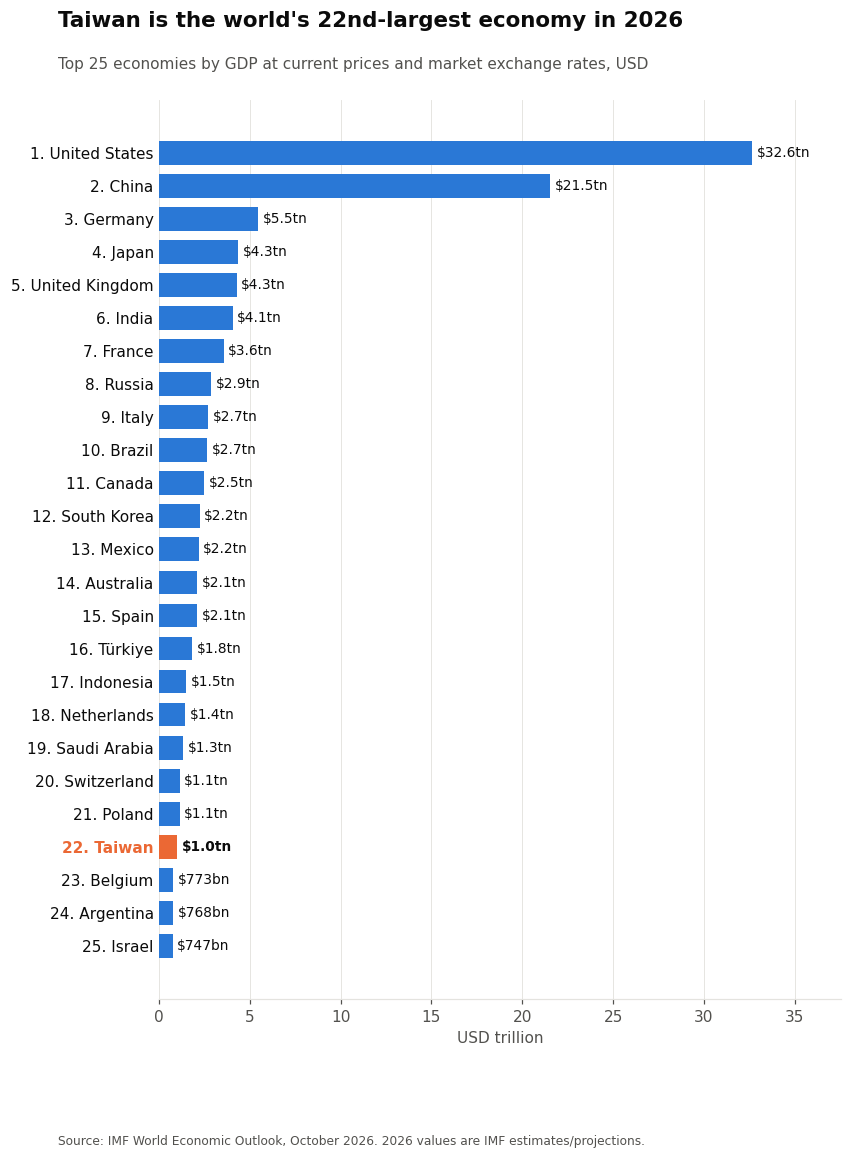

In [12]:
# Chart 1: largest economies by total GDP (enough bars that Taiwan is always visible)
tw_rank = int(df["gdp_usd_bn"].rank(ascending=False, method="min")["TWN"])
n_bars = max(25, tw_rank + 2)
plot = df.sort_values("gdp_usd_bn", ascending=False).head(n_bars).iloc[::-1]
labels = [f"{len(plot) - i}. {n}" for i, n in enumerate(plot["country"])]

fig, ax = plt.subplots(figsize=(8, 0.34 * n_bars + 1))
ax.barh(labels, plot["gdp_usd_bn"] / 1000, height=0.72,
        color=[ORANGE if c == "TWN" else BLUE for c in plot.index])
for y, v in enumerate(plot["gdp_usd_bn"]):
    ax.text(v / 1000 + 0.25, y, money(v), va="center", fontsize=9, color=INK,
            fontweight="bold" if plot.index[y] == "TWN" else "normal")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, plot["gdp_usd_bn"].max() / 1000 * 1.15)
ax.set_xlabel("USD trillion")
highlight_taiwan_label(ax, plot.index)
headline(fig, f"Taiwan is the world's {ordinal(tw_rank)}-largest economy in {YEAR}",
         f"Top {n_bars} economies by GDP at current prices and market exchange rates, USD")
plt.savefig("images/1_top_gdp.png")
plt.show()

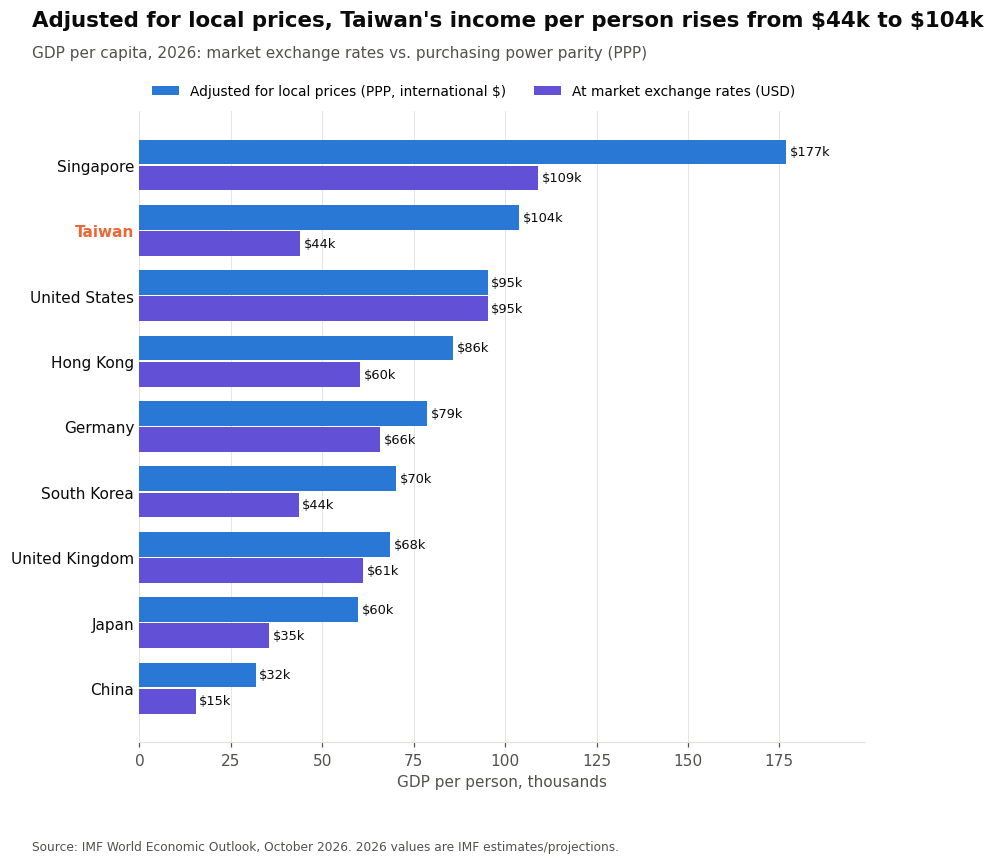

In [13]:
# Chart 2: GDP per capita at market exchange rates vs. PPP, Taiwan and peers
p = df.loc[PEERS].sort_values("gdp_per_capita_ppp")
y = list(range(len(p)))
tw = df.loc["TWN"]

fig, ax = plt.subplots(figsize=(8.5, 7))
ax.barh([i + 0.2 for i in y], p["gdp_per_capita_ppp"] / 1000, height=0.38, color=BLUE,
        label="Adjusted for local prices (PPP, international $)")
ax.barh([i - 0.2 for i in y], p["gdp_per_capita_usd"] / 1000, height=0.38, color=VIOLET,
        label="At market exchange rates (USD)")
for i, (nom, ppp) in enumerate(zip(p["gdp_per_capita_usd"], p["gdp_per_capita_ppp"])):
    ax.text(ppp / 1000 + 1, i + 0.2, f"${ppp / 1000:,.0f}k", va="center", fontsize=8.5, color=INK)
    ax.text(nom / 1000 + 1, i - 0.2, f"${nom / 1000:,.0f}k", va="center", fontsize=8.5, color=INK)
ax.set_yticks(y, p["country"])
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, p["gdp_per_capita_ppp"].max() / 1000 * 1.12)
ax.set_xlabel("GDP per person, thousands")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9)
highlight_taiwan_label(ax, p.index)
headline(fig, f"Adjusted for local prices, Taiwan's income per person rises "
              f"from ${tw['gdp_per_capita_usd'] / 1000:,.0f}k to ${tw['gdp_per_capita_ppp'] / 1000:,.0f}k",
         f"GDP per capita, {YEAR}: market exchange rates vs. purchasing power parity (PPP)", top=0.93)
plt.savefig("images/2_per_capita_nominal_vs_ppp.png")
plt.show()

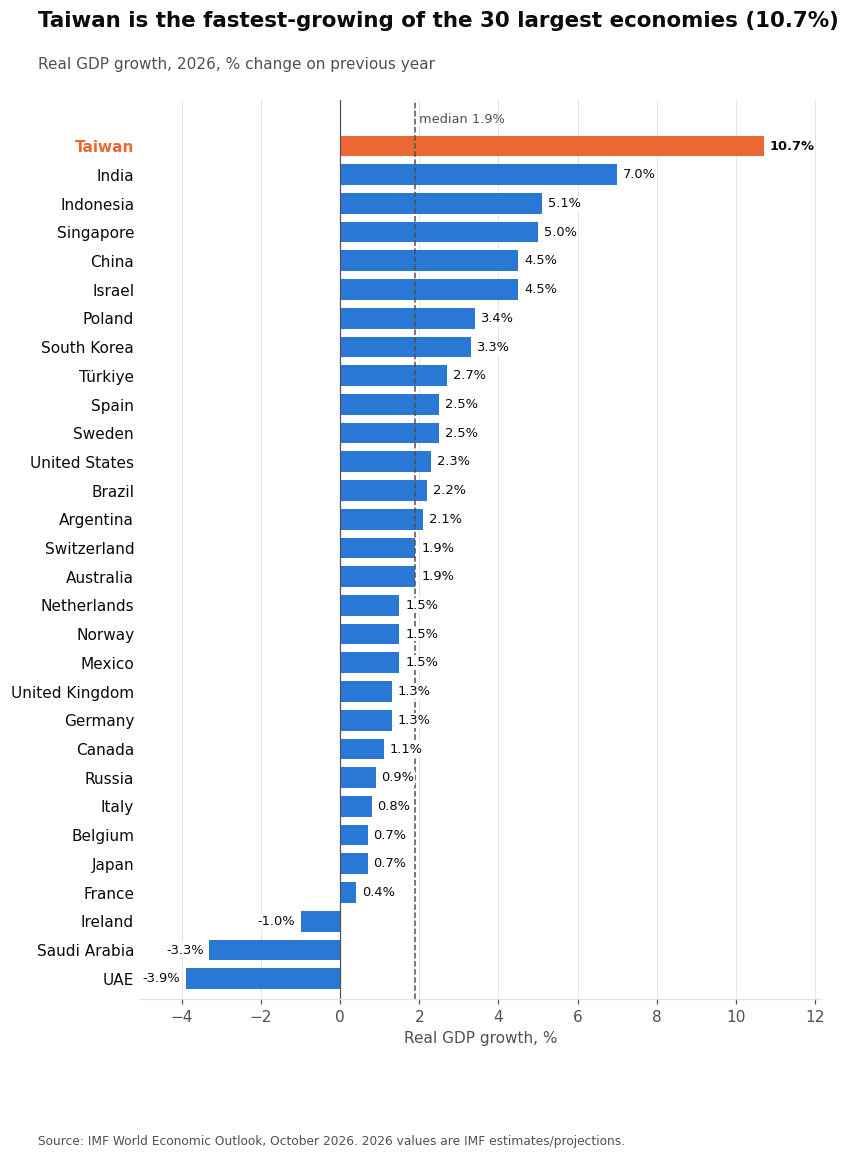

In [14]:
# Chart 3 and 4 share one layout: the 30 largest economies, sorted, with a median line
def ranked_bars(col, title, subtitle, unit_label, filename):
    s = big30[["country", col]].dropna().sort_values(col)
    med = big30[col].median()
    fig, ax = plt.subplots(figsize=(8, 9.5))
    ax.barh(s["country"], s[col], height=0.72, color=[ORANGE if c == "TWN" else BLUE for c in s.index])
    span = s[col].max() - min(s[col].min(), 0)
    for i, (c, v) in enumerate(s[col].items()):
        ax.text(v + (span * 0.01 if v >= 0 else -span * 0.01), i, f"{v:.1f}%",
                va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=INK,
                fontweight="bold" if c == "TWN" else "normal",
                bbox=dict(facecolor="white", edgecolor="none", pad=0.6))   # keeps labels readable over the median line
    ax.axvline(0, color=INK_2, linewidth=0.8)
    ax.axvline(med, color=INK_2, linewidth=1, linestyle="--")
    ax.text(med, len(s) - 0.3, f" median {med:.1f}%", color=INK_2, fontsize=8.5, va="bottom")
    ax.set_xlim(min(s[col].min(), 0) - span * 0.08, s[col].max() + span * 0.1)
    ax.set_ylim(-0.7, len(s) + 0.6)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel(unit_label)
    highlight_taiwan_label(ax, s.index)
    headline(fig, title, subtitle)
    plt.savefig(filename)
    plt.show()


tw_g = df.loc["TWN", "real_growth_pct"]
growth_rank = int((big30["real_growth_pct"] > tw_g).sum()) + 1   # how many big economies grow faster, plus one
title = (f"Taiwan is the fastest-growing of the 30 largest economies ({tw_g:.1f}%)" if growth_rank == 1
         else f"Taiwan ranks {ordinal(growth_rank)} for growth among the 30 largest economies ({tw_g:.1f}%)")
ranked_bars("real_growth_pct", title,
            f"Real GDP growth, {YEAR}, % change on previous year",
            "Real GDP growth, %", "images/3_real_growth_top30.png")

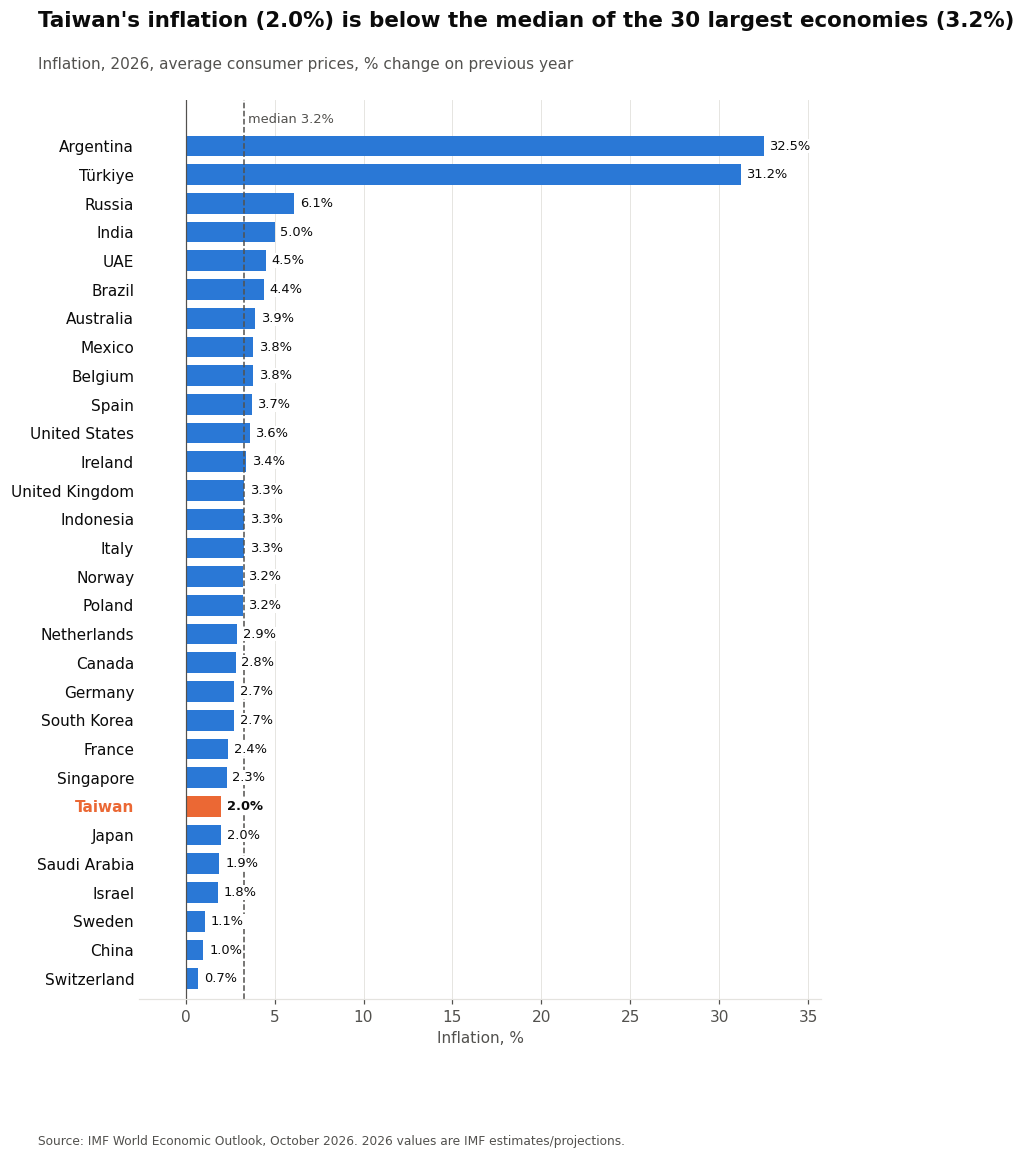

In [15]:
tw_i = df.loc["TWN", "inflation_pct"]
med_i = big30["inflation_pct"].median()
ranked_bars("inflation_pct",
            f"Taiwan's inflation ({tw_i:.1f}%) is {'below' if tw_i < med_i else 'above'} "
            f"the median of the 30 largest economies ({med_i:.1f}%)",
            f"Inflation, {YEAR}, average consumer prices, % change on previous year",
            "Inflation, %", "images/4_inflation_top30.png")

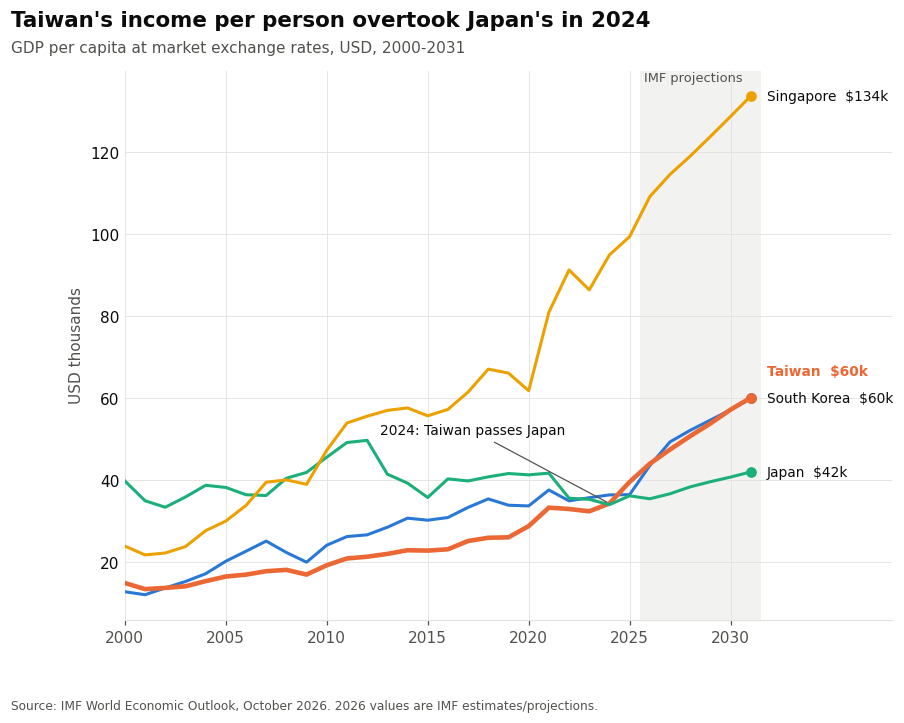

In [16]:
# Chart 5: GDP per capita over time, Taiwan vs. East Asian peers (projections shaded)
trend_codes = {"KOR": BLUE, "TWN": ORANGE, "JPN": AQUA, "SGP": YELLOW}
trend = tables["gdp_per_capita_usd"].loc[list(trend_codes)]
trend = trend[[c for c in trend.columns if 2000 <= int(c) <= 2031]] / 1000
years = [int(c) for c in trend.columns]

# First year Taiwan's GDP per capita moves above Japan's (and stays above)
above = (trend.loc["TWN"] > trend.loc["JPN"])
cross_year = None
for i in range(len(above)):
    if above.iloc[i:].all() and not above.iloc[:i].all():
        cross_year = years[i]
        break

fig, ax = plt.subplots(figsize=(9, 5.8))
ax.axvspan(int(YEAR) - 0.5, years[-1] + 0.5, color=GRID, alpha=0.45, linewidth=0, zorder=0)
for c, color in trend_codes.items():
    ax.plot(years, trend.loc[c], color=color, linewidth=3 if c == "TWN" else 2)
    ax.plot(years[-1], trend.loc[c].iloc[-1], "o", color=color, markersize=6)
if cross_year:
    v = trend.loc["TWN", str(cross_year)]
    ax.annotate(f"{cross_year}: Taiwan passes Japan", (cross_year, v), xytext=(-150, 45),
                textcoords="offset points", fontsize=9, color=INK,
                arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=0.8))

# Direct labels with the latest value, nudged apart so close lines don't overlap
ends = trend.iloc[:, -1].sort_values()
gap = (ends.max() - ends.min() + 1) * 0.07
label_y, last = {}, None
for c, v in ends.items():
    label_y[c] = v if last is None else max(v, last + gap)
    last = label_y[c]
for c, yv in label_y.items():
    ax.text(years[-1] + 0.8, yv, f"{df.loc[c, 'country']}  ${ends[c]:,.0f}k", va="center", fontsize=9,
            color=ORANGE if c == "TWN" else INK, fontweight="bold" if c == "TWN" else "normal")

ax.text(int(YEAR) - 0.3, ax.get_ylim()[1], "IMF projections", va="top", color=INK_2, fontsize=8.5)
ax.set_xlim(years[0], years[-1] + 7)
ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2025, 2030])
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_ylabel("USD thousands")
if cross_year and cross_year <= int(YEAR):
    title = f"Taiwan's income per person overtook Japan's in {cross_year}"
elif cross_year:
    title = f"Taiwan's income per person is projected to overtake Japan's in {cross_year}"
else:
    title = "GDP per capita: Taiwan vs. East Asian peers"
headline(fig, title, "GDP per capita at market exchange rates, USD, 2000-2031")
plt.savefig("images/5_taiwan_peers_trend.png")
plt.show()

## 8. Key numbers (calculated, not typed in)

Every figure quoted in the README comes from this cell, so it updates if the data changes.

In [17]:
tw = df.loc["TWN"]
rk = {r["measure"]: r["rank"] for r in rank_rows}

key = {
    "year": YEAR,
    "n_economies": int(df["gdp_usd_bn"].notna().sum()),
    "top5_gdp": list(df.sort_values("gdp_usd_bn", ascending=False)["country"].head(5)),
    "top5_gdp_per_capita": list(df.sort_values("gdp_per_capita_usd", ascending=False)["country"].head(5)),
    "top5_ppp_per_capita": list(df.sort_values("gdp_per_capita_ppp", ascending=False)["country"].head(5)),
    "usa_gdp_bn": round(df.loc["USA", "gdp_usd_bn"], 1),
    "chn_gdp_bn": round(df.loc["CHN", "gdp_usd_bn"], 1),
    "top10_share_of_world_pct": round(df["gdp_usd_bn"].nlargest(10).sum() / df["gdp_usd_bn"].sum() * 100, 1),
    "taiwan": {
        "gdp_usd_bn": round(tw["gdp_usd_bn"], 1),
        "gdp_per_capita_usd": round(tw["gdp_per_capita_usd"], 0),
        "gdp_per_capita_ppp": round(tw["gdp_per_capita_ppp"], 0),
        "price_level_ratio": round(tw["price_level_ratio"], 2),
        "real_growth_pct": round(tw["real_growth_pct"], 2),
        "inflation_pct": round(tw["inflation_pct"], 2),
        "population_mn": round(tw["population_mn"], 2),
        "rank_gdp": rk["Total GDP (USD bn)"],
        "rank_gdp_per_capita": rk["GDP per capita (USD)"],
        "rank_ppp_per_capita": rk["GDP per capita (PPP, int. $)"],
    },
    "taiwan_growth_rank_in_big30": growth_rank,
    "taiwan_passes_japan_gdp_per_capita_year": cross_year,
    "big30_median_growth_pct": round(big30["real_growth_pct"].median(), 2),
    "big30_median_inflation_pct": round(big30["inflation_pct"].median(), 2),
    "big30_fastest_growth": big30["real_growth_pct"].nlargest(3).round(2).rename(index=country_names).to_dict(),
    "big30_highest_inflation": big30["inflation_pct"].nlargest(3).round(2).rename(index=country_names).to_dict(),
    "peers": df.loc[PEERS, ["gdp_per_capita_usd", "gdp_per_capita_ppp", "price_level_ratio",
                            "real_growth_pct", "inflation_pct"]].round(2).to_dict(orient="index"),
}

with open("data/key_numbers.json", "w") as f:
    json.dump(key, f, indent=2, default=float)
print(json.dumps(key, indent=2, default=float))

{
  "year": "2026",
  "n_economies": 191,
  "top5_gdp": [
    "United States",
    "China",
    "Germany",
    "Japan",
    "United Kingdom"
  ],
  "top5_gdp_per_capita": [
    "Liechtenstein",
    "Luxembourg",
    "Ireland",
    "Switzerland",
    "Norway"
  ],
  "top5_ppp_per_capita": [
    "Liechtenstein",
    "Singapore",
    "Luxembourg",
    "Ireland",
    "Macao SAR"
  ],
  "usa_gdp_bn": 32642.4,
  "chn_gdp_bn": 21546.4,
  "top10_share_of_world_pct": 65.8,
  "taiwan": {
    "gdp_usd_bn": 1019.6,
    "gdp_per_capita_usd": 43951.0,
    "gdp_per_capita_ppp": 103743.0,
    "price_level_ratio": 0.42,
    "real_growth_pct": 10.7,
    "inflation_pct": 2.0,
    "population_mn": 23.2,
    "rank_gdp": 22,
    "rank_gdp_per_capita": 31,
    "rank_ppp_per_capita": 9
  },
  "taiwan_growth_rank_in_big30": 1,
  "taiwan_passes_japan_gdp_per_capita_year": 2024,
  "big30_median_growth_pct": 1.9,
  "big30_median_inflation_pct": 3.25,
  "big30_fastest_growth": {
    "Taiwan Province of China": 10.

## 9. Findings

*Based on the IMF October 2026 WEO; figures are from the key-numbers cell above.*

1. **Size:** Taiwan is the world's **22nd-largest economy** in 2026 (about **USD 1.02 trillion**), between Poland and Belgium. The US (USD 32.6tn) and China (USD 21.5tn) are far ahead of everyone else; the top 10 produce about two-thirds of world GDP.
2. **Growth:** Taiwan is the **fastest-growing of the 30 largest economies (10.7%)**, well above India (7.0%) and the median of 1.9%. The IMF links this to investment in AI and related hardware, which Taiwan exports.
3. **Income per person:** At market exchange rates Taiwan ranks **31st (USD 44k)**, just above South Korea (USD 43.5k) and ahead of Japan (USD 35k). Taiwan passed Japan in 2024.
4. **Purchasing power:** Adjusted for local prices, Taiwan jumps to **9th (USD 104k)**. Its price level is about **42% of the US level**, the lowest among its rich peers, so the same income buys much more at home.
5. **Inflation:** Taiwan's 2.0% is below the median of the 30 largest economies (3.2%), so the growth is not coming with an inflation problem.

<!-- Jane: add your own interpretation here. Good prompts:
- Which ranking surprised you most, and why?
- Why might Taiwan's per-capita income look low in USD but high in PPP?
- What would a bank or investor take from the growth vs. inflation chart?
-->

## 10. Caveats

- **2026 figures are IMF estimates/projections** made in October 2026 and will be revised.
- **Exchange rates move rankings.** Nominal USD figures change when a currency weakens or strengthens, even if the real economy does not.
- **PPP is an estimate.** It relies on price surveys (ICP) that are infrequent; small changes in assumptions shift PPP levels noticeably.
- **Small economies distort per-capita rankings.** Ireland (profits of multinationals booked there; Ireland's own GNI* is far lower) and Luxembourg (cross-border workers counted in output but not population) rank higher than living standards suggest.
- **Missing data:** a few economies have no 2026 figure and are excluded from the rankings (see the data-quality cell).